## Visualização de EEG

Esse primeiro notebook tem como objetivo explorar os registros de EEG da base CHB-MIT, realizando a visualização inicial dos sinais de um registro com crise e um sem, a fim de compreender a estrutura dos dados e auxiliar na escolha dos registros que serão usados nas próximas etapas do projeto.

## 1. Instalação das bibliotecas

Nesta etapa, instalamos a biblioteca MNE-Python, utilizada para leitura, manipulação, processamento e visualização de sinais de eletroencefalograma (EEG).

In [2]:

!pip install mne


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 17.5 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mne]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


## 2. Consulta às anotações do paciente

Realizamos o download do arquivo `chb01-summary.txt`, que contém informações sobre os registros EEG do paciente, incluindo os horários de início e término das crises epilépticas anotadas.

In [1]:
url = "https://physionet.org/files/chbmit/1.0.0/chb01/chb01-summary.txt"

!wget -O chb01-summary.txt $url

with open("chb01-summary.txt", "r") as arquivo:
    resumo = arquivo.read()

print(resumo)

--2026-11-13 12:35:37--  https://physionet.org/files/chbmit/1.0.0/chb01/chb01-summary.txt
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01-summary.txt [following]
--2026-11-13 12:35:38--  https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01-summary.txt
Resolving physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)... 52.216.42.210, 16.15.255.228, 16.15.236.165, ...
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|52.216.42.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5355 (5.2K) [binary/octet-stream]
Saving to: ‘chb01-summary.txt’

chb01-summary.txt   100%[===================>]   5.23K  --.-KB/s    in 0s      

2026-11-13 12:35:38 (79.1 MB/s) - ‘chb01-summary.txt’ saved [5355/5355]

Data Sampling

## 3. Download do primeiro registro EEG

Realizamos o download do arquivo `chb01_01.edf`, paciente 1, pertencente à base pública CHB-MIT Scalp EEG Database.

Os arquivos no formato EDF (European Data Format) armazenam os sinais EEG registrados durante o monitoramento do paciente.

In [2]:

import os

url = "https://physionet.org/files/chbmit/1.0.0/chb01/chb01_01.edf"

!wget -O chb01_01.edf $url


--2026-11-13 12:35:47--  https://physionet.org/files/chbmit/1.0.0/chb01/chb01_01.edf
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01_01.edf [following]
--2026-11-13 12:35:47--  https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01_01.edf
Resolving physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)... 52.217.168.178, 52.217.167.138, 16.15.237.239, ...
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|52.217.168.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 42399744 (40M) [binary/octet-stream]
Saving to: ‘chb01_01.edf’

chb01_01.edf        100%[===================>]  40.44M  56.8MB/s    in 0.7s    

2026-11-13 12:35:48 (56.8 MB/s) - ‘chb01_01.edf’ saved [42399744/42399744]



## 4. Leitura do arquivo EEG

Utilizamos a biblioteca MNE para abrir o arquivo EDF e carregar suas informações.

O registro selecionado pertence ao paciente chb01 e corresponde a uma gravação específica(primeira)  não à totalidade dos dados desse paciente.

In [3]:

import mne

#arquivo 1 sem crise

# Caminho do arquivo
arquivo = "chb01_01.edf"

# Ler o arquivo EDF
raw = mne.io.read_raw_edf(arquivo, preload=False)

# Mostrar informações do registro
print(raw.info)


Extracting EDF parameters from chb01_01.edf...
Setting channel info structure...
Creating raw.info structure...
<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2076-11-06 11:42:54 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>


/tmp/ipykernel_6011/3019779864.py:9: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(arquivo, preload=False)


## 5. Visualização dos sinais EEG

Nesta etapa, visualizamos graficamente os sinais registrados pelos diferentes canais EEG.

O gráfico apresenta a variação da atividade elétrica cerebral ao longo do tempo, permitindo uma inspeção inicial dos dados.

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


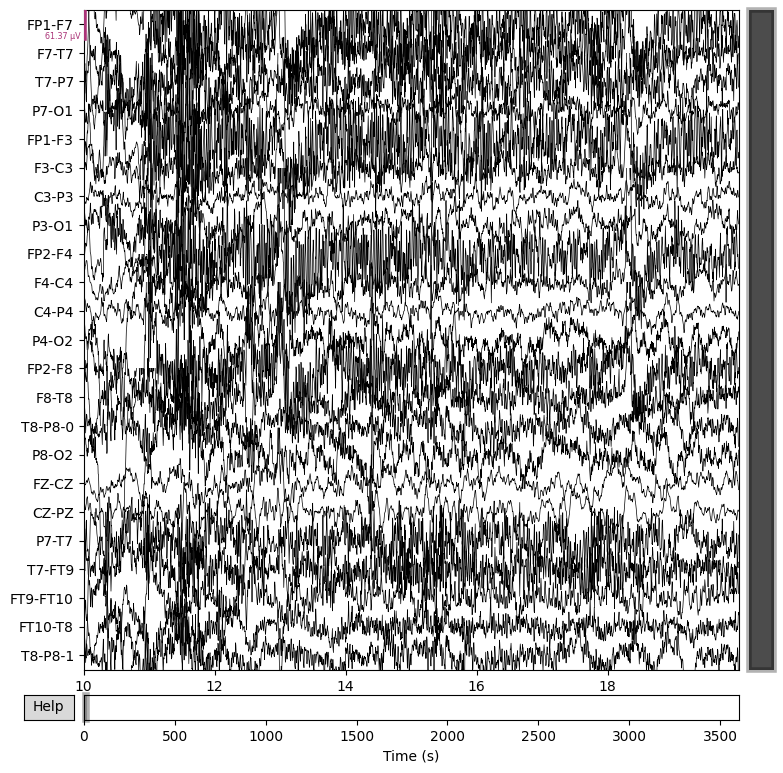

In [12]:
raw.plot(
    duration=10,
    n_channels=23,
    scalings="auto"
);

## 6. Identificação dos metadados do registro

Extraímos informações técnicas do arquivo EEG, incluindo:

- Número de canais registrados;
- Frequência de amostragem;
- Duração total da gravação;
- Identificação dos canais utilizados.

Essas informações ajudam a caracterizar os dados que serão utilizados nas próximas etapas do processamento.

In [7]:
# Quantidade de canais
print("Número de canais:", len(raw.ch_names))

# Frequência de amostragem
print("Frequência:", raw.info["sfreq"], "Hz")

# Duração total
print("Duração:", raw.times[-1], "segundos")

# Nomes dos canais
print("Canais:", raw.ch_names)

Número de canais: 23
Frequência: 256.0 Hz
Duração: 3599.99609375 segundos
Canais: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']


## 7. Seleção de um registro com crise epiléptica

Selecionamos o arquivo `chb01_03.edf`, referente ao mesmo paciente, mas que contém uma crise epiléptica anotada.

A escolha permite explorar registros com períodos ictais e interictais, necessários para a comparação proposta no projeto.

In [8]:
url = "https://physionet.org/files/chbmit/1.0.0/chb01/chb01_03.edf"
!wget -O chb01_03.edf $url

--2026-11-13 12:38:15--  https://physionet.org/files/chbmit/1.0.0/chb01/chb01_03.edf
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01_03.edf [following]
--2026-11-13 12:38:15--  https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01_03.edf
Resolving physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)... 16.182.39.162, 16.15.212.138, 52.217.115.170, ...
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|16.182.39.162|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 42399744 (40M) [binary/octet-stream]
Saving to: ‘chb01_03.edf’

chb01_03.edf        100%[===================>]  40.44M  57.0MB/s    in 0.7s    

2026-11-13 12:38:16 (57.0 MB/s) - ‘chb01_03.edf’ saved [42399744/42399744]



## 8. Leitura do terceiro registro

Realizamos a leitura do arquivo `chb01_03.edf` utilizando a biblioteca MNE.

Para preservar os dados do primeiro registro, armazenamos este arquivo em uma variável independente, chamada `raw_3`.

Extracting EDF parameters from chb01_03.edf...
Setting channel info structure...
Creating raw.info structure...


/tmp/ipykernel_6011/3023352021.py:5: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw_3 = mne.io.read_raw_edf(arquivo, preload=False)


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


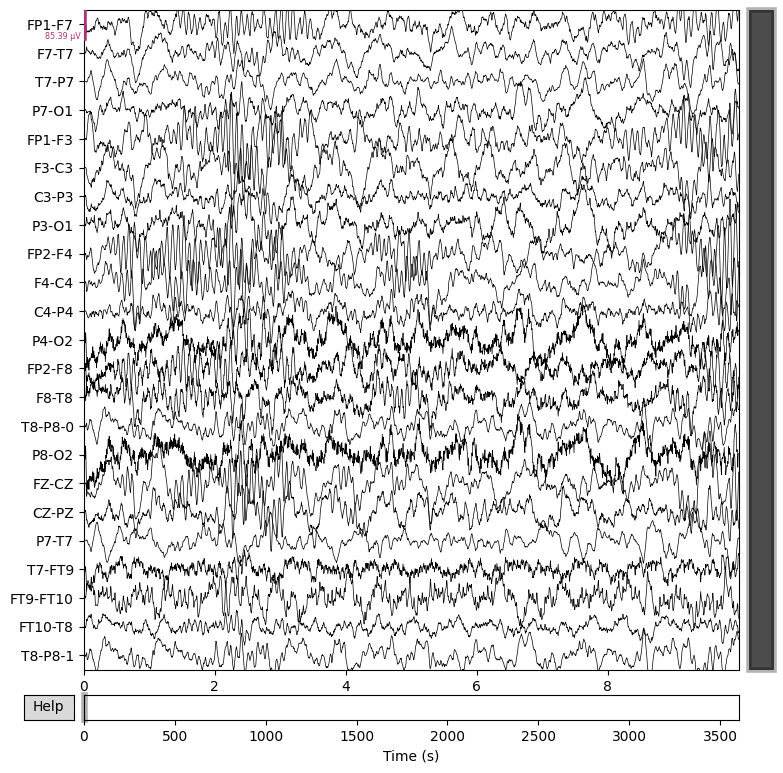

In [10]:
#arquivo 3 com crise

arquivo = "chb01_03.edf"

raw_3 = mne.io.read_raw_edf(arquivo, preload=False)

raw_3.plot(duration=10, n_channels=23, scalings="auto");

Período da crise no registro, de acordo com  arquivo chb01-summary.txt, ínicio da crise em 2996, fim em 3036.

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


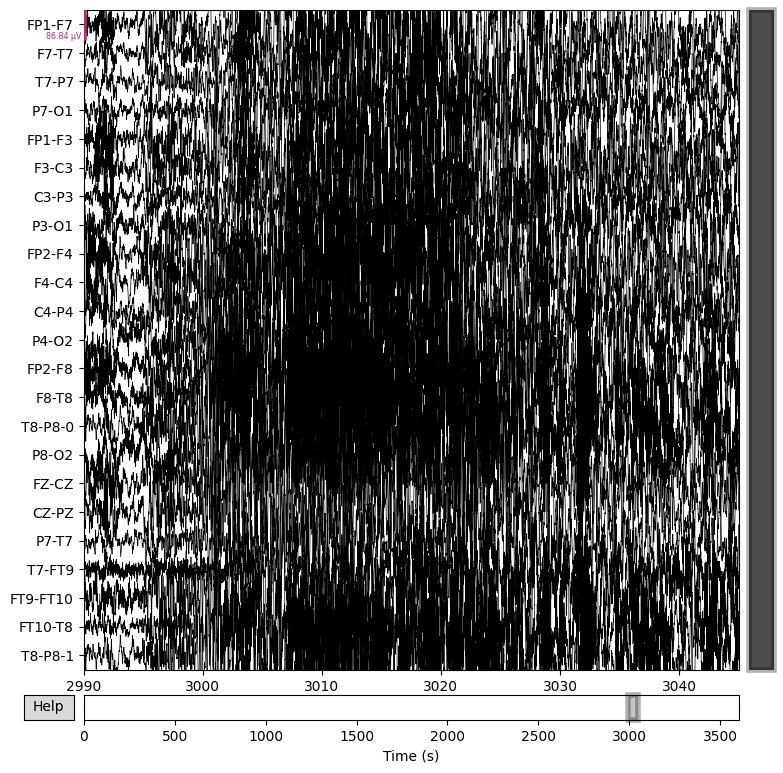

In [16]:
raw_3.plot(
    start=2990,
    duration=55,
    n_channels=23,
    scalings="auto"
);

## 9. Identificação dos metadados do registro

Extraímos informações técnicas do arquivo EEG, incluindo:

- Número de canais registrados;
- Frequência de amostragem;
- Duração total da gravação;
- Identificação dos canais utilizados.

Essas informações ajudam a caracterizar os dados que serão utilizados nas próximas etapas do processamento.

In [11]:
# Número de canais
print("Número de canais:", len(raw_3.ch_names))

# Frequência de amostragem
print("Frequência de amostragem:", raw_3.info["sfreq"], "Hz")

# Duração total
print("Duração:", round(raw_3.times[-1], 2), "segundos")

# Lista dos canais
print("\nCanais:")
print(raw_3.ch_names)

Número de canais: 23
Frequência de amostragem: 256.0 Hz
Duração: 3600.0 segundos

Canais:
['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
